### Exercice 15 — DBSCAN et clusters de forme libre

In [1]:
import numpy as np

import matplotlib.pyplot as plt

from sklearn.datasets import make_moons, make_circles

from sklearn.cluster import KMeans, DBSCAN

from sklearn.preprocessing import StandardScaler

### Générer les trois datasets

In [2]:
X_moons, y_moons = make_moons(

    n_samples=300,

    noise=0.08,

    random_state=3

)

X_circles, y_circles = make_circles(

    n_samples=300,

    noise=0.05,

    factor=0.5,

    random_state=3

)

theta = np.linspace(0, 4*np.pi, 150)

r = theta

x1 = r * np.cos(theta)

y1 = r * np.sin(theta)

x2 = -r * np.cos(theta)

y2 = -r * np.sin(theta)

X_spirals = np.vstack([

    np.column_stack([x1, y1]),

    np.column_stack([x2, y2])

])

rng = np.random.default_rng(3)

X_spirals += rng.normal(

    loc=0,

    scale=0.25,

    size=X_spirals.shape
    
)

### Prépareration des datasets

In [6]:
datasets = {
    "Moons": X_moons,

    "Circles": X_circles,
    
    "Spirales": X_spirals
}

datasets

{'Moons': array([[-2.06127757e-01,  9.94183565e-01],
        [ 8.27534687e-01, -5.15703083e-01],
        [ 7.16022088e-01, -4.39881621e-01],
        [ 2.02102398e+00,  3.45918337e-01],
        [ 8.39319249e-01,  5.48578302e-01],
        [-8.50143506e-01,  2.62291179e-01],
        [ 5.68632158e-01, -2.83440590e-01],
        [ 1.52986796e+00, -2.77015281e-01],
        [ 8.38372092e-01,  3.41292311e-01],
        [ 1.42325663e-01, -7.74739052e-02],
        [ 7.93717400e-01,  5.17863854e-01],
        [-5.50962694e-01,  7.47623588e-01],
        [ 1.47102774e+00, -3.18008588e-01],
        [-8.16667567e-02,  9.93404402e-01],
        [ 2.32219886e-01,  9.51523024e-01],
        [-6.68466115e-01,  6.34587607e-01],
        [ 1.56769233e+00, -3.01471833e-01],
        [ 1.11809555e+00, -4.55904386e-01],
        [-1.10654627e-01,  5.12164154e-01],
        [ 3.03614967e-01,  8.53718035e-01],
        [ 2.35208653e-01,  1.01546797e+00],
        [ 1.14544773e+00, -4.73853975e-01],
        [ 5.07832932e-0

### Normalisation

In [4]:
datasets_scaled = {}

for name, X in datasets.items():

    scaler = StandardScaler()

    datasets_scaled[name] = scaler.fit_transform(X)

### Appliquer K-Means et DBSCAN

In [5]:
dbscan_params = {
    "Moons": {
        "eps": 0.25,
        "min_samples": 5
    },

    "Circles": {
        "eps": 0.18,
        "min_samples": 5
    },

    "Spirales": {
        "eps": 0.10,
        "min_samples": 5
    }
}

### Entrainement

In [7]:
results = {}

for name, X in datasets_scaled.items():

    km = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=10
    )

    km_labels = km.fit_predict(X)

    db = DBSCAN(**dbscan_params[name])

    db_labels = db.fit_predict(X)

    results[name] = {
        "KMeans": km_labels,
        "DBSCAN": db_labels
    }

### Visualisation

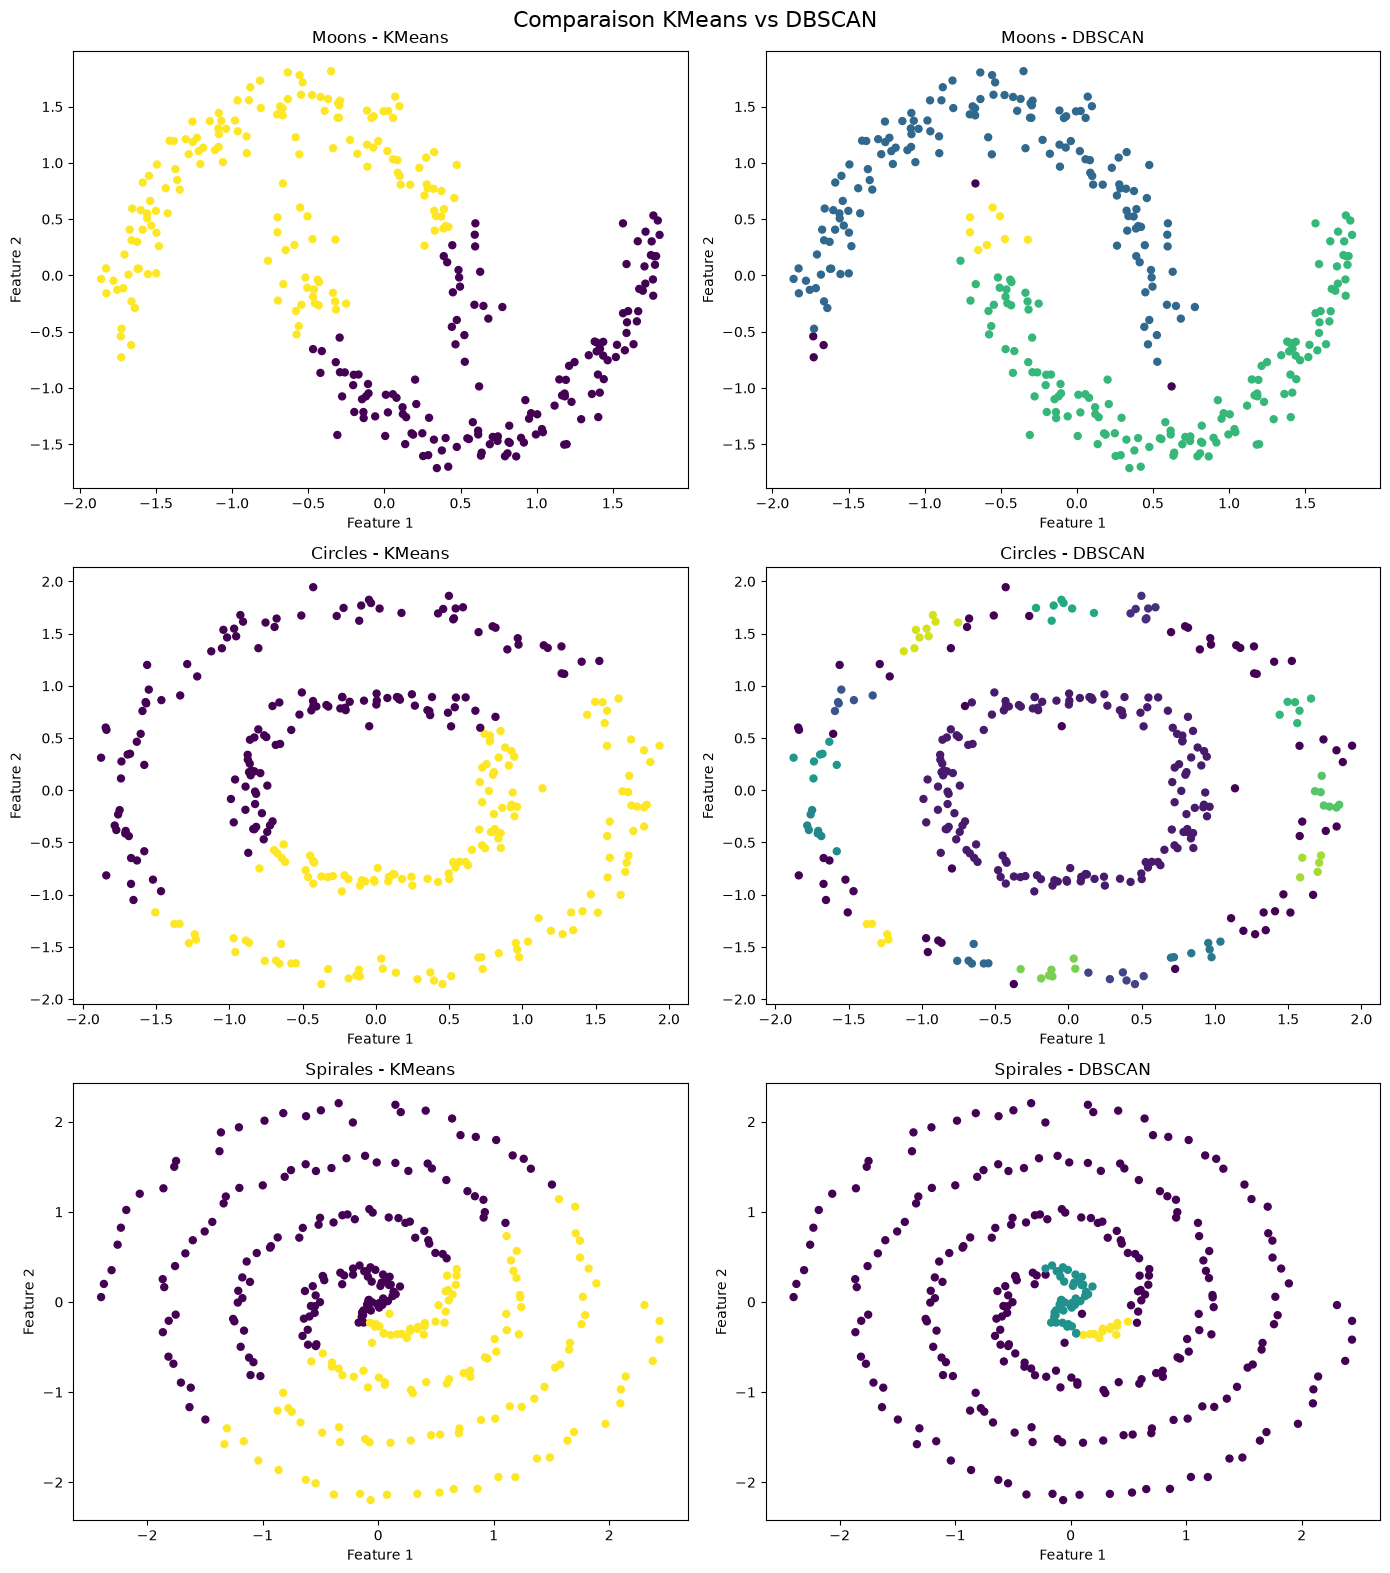

In [9]:
fig, axes = plt.subplots(

    3, 2,

    figsize=(14, 16)

)

for i, (name, X) in enumerate(datasets_scaled.items()):

    axes[i, 0].scatter(

        X[:, 0],

        X[:, 1],

        c=results[name]["KMeans"],

        cmap="viridis",

        s=25
    )

    axes[i, 0].set_title(f"{name} - KMeans")

    axes[i, 1].scatter(

        X[:, 0],

        X[:, 1],

        c=results[name]["DBSCAN"],

        cmap="viridis",

        s=25
    )

    axes[i, 1].set_title(f"{name} - DBSCAN")

    axes[i, 0].set_xlabel("Feature 1")

    axes[i, 0].set_ylabel("Feature 2")

    axes[i, 1].set_xlabel("Feature 1")

    axes[i, 1].set_ylabel("Feature 2")

plt.suptitle(

    "Comparaison KMeans vs DBSCAN",
    
    fontsize=16
)

plt.tight_layout()

### Comparaison du nombre de clusters et le bruit

In [10]:
for name in datasets_scaled:

    km_labels = results[name]["KMeans"]

    db_labels = results[name]["DBSCAN"]

    n_clusters = len(set(db_labels) - {-1})
    
    n_noise = np.sum(db_labels == -1)

    print(f"\nDataset : {name}")

    print("KMeans clusters :", len(np.unique(km_labels)))

    print("DBSCAN clusters :", n_clusters)

    print("DBSCAN bruit :", n_noise)


Dataset : Moons
KMeans clusters : 2
DBSCAN clusters : 3
DBSCAN bruit : 5

Dataset : Circles
KMeans clusters : 2
DBSCAN clusters : 15
DBSCAN bruit : 61

Dataset : Spirales
KMeans clusters : 2
DBSCAN clusters : 2
DBSCAN bruit : 242
